# Machine Learning for Liquid Biopsy Research


**ColoMARK PhD Network** &middot; Workshop on Mendelian Randomisation & Machine Learning
School of Biomolecular and Biomedical Science, University College Dublin &middot; 6 November 2026

Session lead: **Maryam Abbasi**, CIAC-PLDIS, Polytechnic University of Santarem

---

## The problem we are going to solve

> Your clinic receives patients referred with possible colorectal cancer.
> Colonoscopy capacity is limited, so somebody has to decide **who gets scoped
> first**.
>
> You have a blood sample from each patient and a handful of measurements from it.
>
> **Can you build something that ranks patients by risk &mdash; and, more importantly,
> can you tell whether that something is trustworthy?**

Everything in this notebook works towards that one problem. You will build a
model, then spend just as long learning the ways it can quietly lie to you.

By the end you will be able to:

1. Write and read basic Python
2. Define a prediction question properly
3. Build a complete, correct machine-learning workflow
4. Evaluate it honestly
5. **Spot the mistakes that make published biomarker studies irreproducible**

Point 5 is the one that will matter most in your career.

---

## How to use this notebook

Work through it **top to bottom**. Do not skip ahead &mdash; later cells depend on
earlier ones having been run.

Each topic follows the same four steps:

| Step | What it looks like |
|---|---|
| **1. The idea** | A short explanation, in plain language |
| **2. See it work** | A code cell marked **RUN THIS** &mdash; just run it |
| **3. Your turn** | A cell with a gap for you to fill in, with hints |
| **4. Check** | A collapsible **Show the solution** box |

Some exercises are harder. Those have an **ASK AN AI** box: a ready-made prompt
you can paste into ChatGPT, Claude or Gemini to get code, which you then paste
back into the notebook and run. **This is a real skill, not cheating** &mdash; getting
code from an AI and then checking whether it is correct is how a lot of research
code gets written now. The checking is the part that matters.

> **Honest advice:** resist the urge to open the solution immediately. The
> struggle is where the learning happens. Give each exercise a real attempt first,
> even a wrong one.

---

## Before you start

**How to run a cell:** click on it, then press **Shift + Enter**. A `[*]` on the
left means it is still running; a number means it finished.

**If you get red text:** that is an error, not a disaster. Read the **last line**
&mdash; that is where the real problem is named. The most common cause by far is
running cells out of order. Fix: *Runtime &rarr; Restart and run all*.

---

> **About the data in this notebook.** The dataset is **synthetic** &mdash; generated
> by code, not collected from people. It contains **no real patients and no
> validated biomarkers**. The variable names are realistic so the work feels
> familiar, but no result produced here is clinical evidence, and nothing here
> supports any diagnostic or treatment decision.

---
---
# MODULE 0 &mdash; Does everything work?

Run the cell below. If it prints a list of version numbers and "Ready", you are
set up and can continue.

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 42               # fixes the randomness so everyone gets the same numbers
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 110)
pd.set_option("display.max_columns", 30)

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print()
print("Ready. Nothing to install, no internet needed.")

---
---
# MODULE 1 &mdash; Python in 25 minutes

Six ideas. That is honestly all the Python the rest of this notebook needs.

If you already write Python, skim this and jump to Module 2.

## 1.1 Variables &mdash; giving things names

### The idea

A **variable** is a name attached to a value. Writing `age = 62` means *"from now
on, the name `age` refers to 62"*.

The `=` is not "equals" in the mathematical sense. It is an instruction: **store
this**.

`print(...)` displays whatever you put in the brackets.

```
    age  =  62
     |      |
   the     the
   name   value
```

In [ ]:
# RUN THIS
patient_id = "CM0001"          # text goes in quotes
age = 62                       # a whole number: no quotes
ctdna_vaf = 0.0086             # a decimal number

print("Patient:", patient_id)
print("Age:", age)
print("ctDNA VAF:", ctdna_vaf)

**YOUR TURN 1.1**

Create a variable called `cea` and give it the value `2.47`, then print it with a
label.

**HINT:** copy the shape of the lines above. Name, `=`, value. Then
`print("CEA:", cea)`.

In [ ]:
# YOUR TURN - write your code below, then press Shift + Enter

cea = None          # <-- replace None with 2.47


# ---- leave this part alone: it checks your answer ----
if cea is None:
    print("Not done yet. Replace None above with 2.47, then re-run this cell.")
else:
    print("CEA:", cea)
    print("Correct!" if cea == 2.47 else "Close - check the number.")

<details>
<summary><b>Show the solution</b></summary>

```python
cea = 2.47
print("CEA:", cea)
```

</details>

## 1.2 Numbers and text are different things

### The idea

Python treats numbers and text differently, and this catches everybody once.

- `5 + 5` gives `10`
- `"5" + "5"` gives `"55"` &mdash; because for text, `+` means *stick together*

**If it has quotes around it, it is text**, whatever it looks like.

To put a number inside a sentence neatly, use an **f-string**: an `f` just before
the opening quote, and the variable name in curly brackets.

```python
f"the value is {vaf}"
```

In [ ]:
# RUN THIS
vaf = 0.0086
cea = 2.47

print(vaf + cea)                      # numbers: adds them

print(f"VAF is {vaf} and CEA is {cea}")

# :.3f means "show 3 decimal places"
print(f"Their ratio is {cea / vaf:.1f}")

# the classic mistake:
print("5" + "5")                      # text, so it sticks together

**YOUR TURN 1.2**

Print a sentence like: `Patient CM0001 is 62 years old`
using the variables `patient_id` and `age` from section 1.1.

**HINT:** `f"Patient {patient_id} is {age} years old"` &mdash; put that inside
`print(...)`.

In [ ]:
# YOUR TURN

sentence = None          # <-- replace None with your f-string


# ---- check ----
if sentence is None:
    print("Not done yet. Replace None above.")
else:
    print(sentence)

<details>
<summary><b>Show the solution</b></summary>

```python
sentence = f"Patient {patient_id} is {age} years old"
print(sentence)
```

</details>

## 1.3 Lists &mdash; several values under one name

### The idea

A **list** holds several values in order, inside square brackets `[ ]`.

Two things to know:

1. **Python counts from 0.** The first item is item `0`.
2. `-1` means **the last item**.

```
   markers = ["ctdna_vaf", "methyl_score", "cea_ng_ml"]
                  |              |              |
   position:      0              1              2
                 -3             -2             -1
```

In [ ]:
# RUN THIS
markers = ["ctdna_vaf", "methyl_score", "cea_ng_ml", "crp_mg_l"]

print("the whole list:", markers)
print("how many:      ", len(markers))
print("the FIRST one: ", markers[0])      # 0, not 1
print("the third one: ", markers[2])
print("the LAST one:  ", markers[-1])

**YOUR TURN 1.3**

Get the **second** marker out of the list (`methyl_score`) and store it in a
variable called `second_marker`.

**HINT:** the second item is at position **1**, because counting starts at 0.

In [ ]:
# YOUR TURN

second_marker = None          # <-- replace None, use markers[...]


# ---- check ----
if second_marker is None:
    print("Not done yet. Replace None above.")
elif second_marker == "methyl_score":
    print("Correct! You got:", second_marker)
else:
    print("You got:", second_marker, "- remember Python counts from 0.")

<details>
<summary><b>Show the solution</b></summary>

```python
second_marker = markers[1]
```

Position 1 is the *second* item, because position 0 is the first.

</details>

## 1.4 Loops &mdash; doing the same thing to everything

### The idea

A **loop** repeats an instruction for every item in a list. This is why a
computer can apply one rule to 240 patients without anybody typing it 240 times.

Two details, both about layout:

- the first line ends with a **colon** `:`
- the repeated part is **indented** (pushed in) underneath

```
for marker in markers:
    print(marker)
^^^                      the colon matters
    ^^^^                 the indent matters
```

Read it as: *"for each item in `markers`, call it `marker`, and do the indented
part"*.

In [ ]:
# RUN THIS
markers = ["ctdna_vaf", "methyl_score", "cea_ng_ml", "crp_mg_l"]

for marker in markers:
    print("Checking:", marker)

print("Done. Checked", len(markers), "markers.")

**YOUR TURN 1.4**

Loop over this list of VAF values and print each one **multiplied by 100**
(to turn it into a percentage).

**HINT:** start with `for v in vaf_values:` then an indented
`print(v * 100)`.

In [ ]:
# YOUR TURN
vaf_values = [0.004, 0.019, 0.0001, 0.071]

# write your loop below this line
done = False          # <-- change to True once you have written the loop



# ---- check ----
if not done:
    print("Not done yet. Write the loop above, then set done = True.")
else:
    print("\nGreat - compare your output with the solution.")

<details>
<summary><b>Show the solution</b></summary>

```python
vaf_values = [0.004, 0.019, 0.0001, 0.071]

for v in vaf_values:
    print(v * 100)
```

A nicer version, with a label and 2 decimal places:

```python
for v in vaf_values:
    print(f"VAF {v} = {v * 100:.2f}%")
```

</details>

## 1.5 Functions &mdash; work somebody already did for you

### The idea

A **function** is a named piece of work that already exists. You *call* it by
writing its name, round brackets, and what you want it to work on.

You have already called two: `print()` and `len()`.

Almost everything in the rest of this notebook is a function call. Machine
learning in Python is mostly **knowing which function to call and what to give
it**, not writing clever code yourself.

```
       np.mean(  vaf_values  )
          |            |
      the name     what you
      of the       give it
      function
```

`np.mean` means *"the `mean` function, which lives inside the `numpy` toolbox
(which we nicknamed `np`)"*. The dot means "inside".

In [ ]:
# RUN THIS
vaf_values = [0.004, 0.019, 0.0001, 0.071]

print("how many :", len(vaf_values))
print("biggest  :", max(vaf_values))
print("smallest :", min(vaf_values))
print("mean     :", np.mean(vaf_values))
print("rounded  :", round(np.mean(vaf_values), 4))

**YOUR TURN 1.5**

Use a function to find the **median** of `vaf_values`.

**HINT:** it is `np.median(...)`, used exactly like `np.mean(...)`.

In [ ]:
# YOUR TURN

the_median = None          # <-- replace None


# ---- check ----
if the_median is None:
    print("Not done yet. Replace None above.")
else:
    print("median:", the_median)
    print("Correct!" if abs(the_median - 0.0115) < 1e-9 else "Hmm - check the function name.")

<details>
<summary><b>Show the solution</b></summary>

```python
the_median = np.median(vaf_values)
```

The median of `[0.004, 0.019, 0.0001, 0.071]` is `0.0115` &mdash; the average of the
two middle values once sorted.

</details>

## 1.6 Tables &mdash; the DataFrame

### The idea

A **DataFrame** is a table: rows and columns, like a spreadsheet. It comes from
the `pandas` toolbox (nicknamed `pd`), and it is how essentially all data is
handled in Python.

For us: **one row per patient, one column per measurement.**

```
            age    ctdna_vaf   cea_ng_ml    crc
   CM0001    62      0.0086       2.47        1     <- one patient
   CM0002    58      0.0021       1.80        0
   CM0003    71      0.0043       3.10        1
     ^
   one row = one patient        ^
                             one column = one measurement
```

Four things you will use constantly:

| What you want | How to write it |
|---|---|
| the first 5 rows | `df.head()` |
| how big is it | `df.shape` &rarr; `(rows, columns)` |
| one column | `df["age"]` |
| count each value in a column | `df["crc"].value_counts()` |

In [ ]:
# RUN THIS - a tiny table, built by hand
small_table = pd.DataFrame({
    "patient_id": ["CM0001", "CM0002", "CM0003", "CM0004", "CM0005"],
    "age":        [62, 58, 71, 49, 66],
    "ctdna_vaf":  [0.0086, 0.0021, 0.0043, 0.0009, 0.0150],
    "crc":        [1, 0, 1, 0, 1],
})

print("shape (rows, columns):", small_table.shape)
print()
print("the age column:")
print(small_table["age"])
print()
small_table

**YOUR TURN 1.6**

Count how many patients in `small_table` have cancer and how many do not.

**HINT:** `small_table["crc"].value_counts()` &mdash; the `crc` column holds
`1` for cancer and `0` for no cancer.

In [ ]:
# YOUR TURN

counts = None          # <-- replace None


# ---- check ----
if counts is None:
    print("Not done yet. Replace None above.")
else:
    print(counts)
    print("\n(You should see 3 patients with 1, and 2 patients with 0.)")

<details>
<summary><b>Show the solution</b></summary>

```python
counts = small_table["crc"].value_counts()
print(counts)
```

</details>

---
### End of Module 1

That is the whole toolkit:

**variables &middot; text vs numbers &middot; lists &middot; loops &middot;
function calls &middot; tables**

Everything from here is one of those six things with a longer name. If a line of
code later looks frightening, it is almost always just a function call with a
long name and several inputs.

---
---
# MODULE 2 &mdash; What exactly are we asking?

No code in this module. It is the most important one anyway.

## 2.1 Two different questions

Almost every confused machine-learning paper in clinical research comes from
mixing up these two:

| | **Prediction** | **Explanation** |
|---|---|---|
| The question | What is likely to be true for *this* person, from what I can measure now? | Does this variable **cause** the outcome? |
| Success means | Accurate on **new, unseen** people | An unbiased effect estimate |
| Typical tool | A classifier (what we build today) | Causal design, RCT, Mendelian randomisation |
| A good result tells you | The model might be useful in a defined setting | The variable might be a mechanism or a target |
| A good result does **not** tell you | Anything about mechanism | Anything about predicting individuals |

**The thing to remember:**

> A model that predicts an outcome well tells you the measured variables carry
> **information** about it. That information might come from a cause. It might
> also come from a consequence, from the care pathway, from a batch effect, or
> from how the cohort was assembled. **The model cannot tell the difference and
> does not try to.**

This is where today's session separates from this morning's Mendelian
randomisation. MR is built to support a causal claim, and pays for it with
assumptions you can write down and test. A classifier makes no causal claim and
offers no such assumptions. Neither replaces the other.

## 2.2 Five things to write down before any modelling

If you cannot fill all five in, modelling is premature.

| | Our problem |
|---|---|
| **Population** | Adults referred to a symptomatic colorectal clinic, before colonoscopy |
| **Outcome** | Colorectal cancer confirmed at colonoscopy within 3 months (`crc`: 1 = yes, 0 = no) |
| **Prediction time point** | The moment the blood is drawn &mdash; **before** any colonoscopy or imaging |
| **Intended use** | Triage: rank referrals so higher-risk patients are scoped first. **Not** a diagnosis. |
| **Predictors** | Only what is known at that moment: demographics, routine bloods, assay readouts |

## 2.3 The one that breaks studies: the prediction time point

Anything recorded **after** the blood draw is contaminated by knowledge of what
happened next &mdash; even things that look purely administrative.

Our dataset contains a column called `days_to_colonoscopy`. Patients whose
results worried somebody were scoped faster. It is a real column in a real
database, it predicts the outcome beautifully, and using it produces a
triumphant, worthless result.

We will do exactly that, on purpose, in Module 8.

> **The test to apply to every candidate predictor:**
>
> *Could I have written this value down on the day the blood was taken, without
> knowing what happened afterwards?*
>
> If no, it is not a predictor.

## 2.4 Small samples, many measurements

This is the defining statistical problem of liquid-biopsy work.

### The problem in one sentence

The more measurements you let the model choose from, the easier it is for a
useless measurement to look useful by accident &mdash; and the fewer patients you
have, the easier that becomes.

### Your real sample size is the smaller group

Imagine a study with 1,000 patients, but only 20 of them have cancer.

The model can only learn what cancer looks like from those **20 people**. The
other 980 tell it what normal looks like, but nothing about the disease.

So the real sample size is 20, not 1,000. The smaller group is what limits you.
We call those **events**.

### Why many measurements is risky

If you measure 800 markers on a small group of patients, some of them will
separate cancers from controls very well **just by chance**.

A simple way to see it: if you test 800 markers and call anything with p < 0.05
significant, about **40 of them will look significant even if none of them mean
anything at all**. That is what 5% of 800 is.

The model cannot tell those 40 apart from a real signal. Neither can you, by
looking at the result.

### The rule of thumb

> You want **at least 10 events for every measurement the model considers.**

So with 60 cancers, you can reasonably consider about 6 measurements.

### The part that catches people

Here is a very reasonable-sounding mistake:

> *"I measured 800 markers, ran a quick test, kept the best 10, and built the
> model on those 10. I have 60 cancers and 10 predictors, so 6 events per
> predictor. That is acceptable."*

It is not. Those 10 were chosen **because they looked good in this particular
dataset**. The choosing is part of the analysis, and it already used the data.

The honest count is 60 events against **800** candidates, not 10.

**"Candidate" means every measurement you looked at, not only the ones you
kept.** You will see exactly how badly this fails in Module 8.2.

### Why this is dangerous rather than simply wrong

Nothing crashes. There is no warning and no error message.

You get a model that works beautifully on your data and fails on everybody
else's &mdash; and you find out two years later, when somebody tries to repeat it.

### Our dataset today

| | |
|---|---|
| Patients | 240 &mdash; sounds comfortable |
| **Cancers (events)** | **63** &mdash; this is the number that matters |
| Measurements | 13 |
| Events per measurement | 63 / 13 = **4.8** |
| Rule of thumb | at least 10 |

This dataset was built to be generous, and it is still at half the recommended
ratio. A real methylation panel on a real cohort is often far worse.

**If a comfortable teaching dataset is already below the line, your own data
probably is too.**

### What to do about it

- Choose your measurements **before** you open the data, and write the list down
- Keep the list short &mdash; it is better to test 5 markers properly than 800 badly
- Report how many you **looked at**, not only how many you kept
- If you must screen many markers, do the screening inside the model (Module 8.2)

**YOUR TURN 2** &mdash; no code, just thinking. Take 3 minutes.

Write the five lines for **your own** project:

```
Population:
Outcome:
Prediction time point:
Intended use:
Predictors available at that time point:
```

Then answer honestly: **which one was hardest to fill in?**

<details>
<summary><b>Show what the common answers mean</b></summary>

**"I cannot name a prediction time point."**
The most common answer, and a useful one. Your question is probably explanatory,
not predictive. That is completely legitimate &mdash; it just means a classifier is
the wrong instrument for it.

**"My intended use is 'understand which markers matter'."**
Then your output is a hypothesis-generating list, and it needs a stability
analysis (does the list survive resampling?), not a ROC curve.

**"Some of my predictors are recorded after diagnosis."**
You have found a leak. Module 8 is about exactly this.

</details>

---
---
# MODULE 3 &mdash; Meet the data

## 3.1 Where it comes from

Real liquid-biopsy cohorts cannot be shared openly, run offline in a classroom,
or contain a leak planted on purpose for teaching. So we generate one.

The cell below builds **240 synthetic patients**. It is long, but you do not need
to understand every line &mdash; read the column names and the comments.

What matters: it deliberately contains the problems you will meet in real data.

- missing values
- class imbalance (only 26% have cancer)
- three technical columns that carry **no** information at all
- a group of "low shedder" cancers that look just like controls on the assay
- one **leaky** column

In [ ]:
# RUN THIS - builds the synthetic dataset
def make_colomark_data(n=240, random_state=RANDOM_STATE):
    """Create a SYNTHETIC colorectal liquid-biopsy teaching dataset.

    NOT real patients. NOT validated biomarkers.
    """
    rng = np.random.default_rng(random_state)

    # The outcome first: about 25% of this clinic population have cancer
    y = (rng.random(n) < 0.25).astype(int)

    # A third of the cancers are "low shedders" - they look like controls.
    # This is what makes the task realistically hard.
    low_shedder = np.zeros(n, dtype=bool)
    low_shedder[y == 1] = rng.random(int(y.sum())) < 0.35
    eff = np.where(y == 1, np.where(low_shedder, 0.25, 1.0), 0.0)

    df = pd.DataFrame({
        "patient_id":            [f"CM{i:04d}" for i in range(1, n + 1)],
        # --- known at the blood draw
        "age":                   np.clip(rng.normal(62, 10, n) + 3 * y, 30, 90).round(0),
        "sex":                   rng.choice(["F", "M"], n, p=[0.47, 0.53]),
        "bmi":                   np.clip(rng.normal(26.5, 4.0, n), 16, 45).round(1),
        # --- liquid-biopsy assay readouts
        "ctdna_vaf":             np.exp(rng.normal(-6.2 + 1.40 * eff, 1.0, n)).round(5),
        "cfdna_conc_ng_ml":      np.exp(rng.normal(1.9 + 0.35 * eff, 0.5, n)).round(1),
        "methyl_score":          (rng.normal(0, 1, n) + 0.85 * eff).round(3),
        "fragment_ratio":        (rng.normal(0.52, 0.045, n) - 0.021 * eff).round(3),
        # --- routine bloods
        "cea_ng_ml":             np.exp(rng.normal(0.55 + 0.65 * eff, 0.65, n)).round(2),
        "platelet_count":        np.clip(rng.normal(255, 62, n) + 16 * eff, 90, 600).round(0),
        "crp_mg_l":              np.exp(rng.normal(0.65 + 0.38 * eff, 0.9, n)).round(2),
        # --- technical columns carrying NO signal whatsoever
        "assay_qc_score":        rng.normal(0, 1, n).round(3),
        "sample_storage_months": np.abs(rng.normal(0, 1, n) * 6 + 9).round(1),
        "lab_tech_index":        rng.normal(0, 1, n).round(3),
        # --- RECORDED AFTER THE PREDICTION TIME POINT. Not a predictor!
        "days_to_colonoscopy":   np.clip(rng.normal(np.where(y == 1, 13, 44),
                                                    np.where(y == 1, 6, 15), n), 2, 120).round(0),
        # --- the outcome
        "crc":                   y,
    })

    # Real clinical data always has gaps
    df.loc[rng.random(n) < 0.18, "cea_ng_ml"] = np.nan
    df.loc[rng.random(n) < 0.11, "crp_mg_l"] = np.nan
    return df


data = make_colomark_data()

print("SYNTHETIC DATA - no real patients, no validated biomarkers.")
print("rows (patients), columns:", data.shape)
data.head()

## 3.2 Look before you model

Two minutes of looking saves two weeks of debugging. Four questions:

1. Is the **outcome** coded the way I think?
2. How **imbalanced** are the groups?
3. Where are the **missing values**?
4. Does anything look obviously wrong?

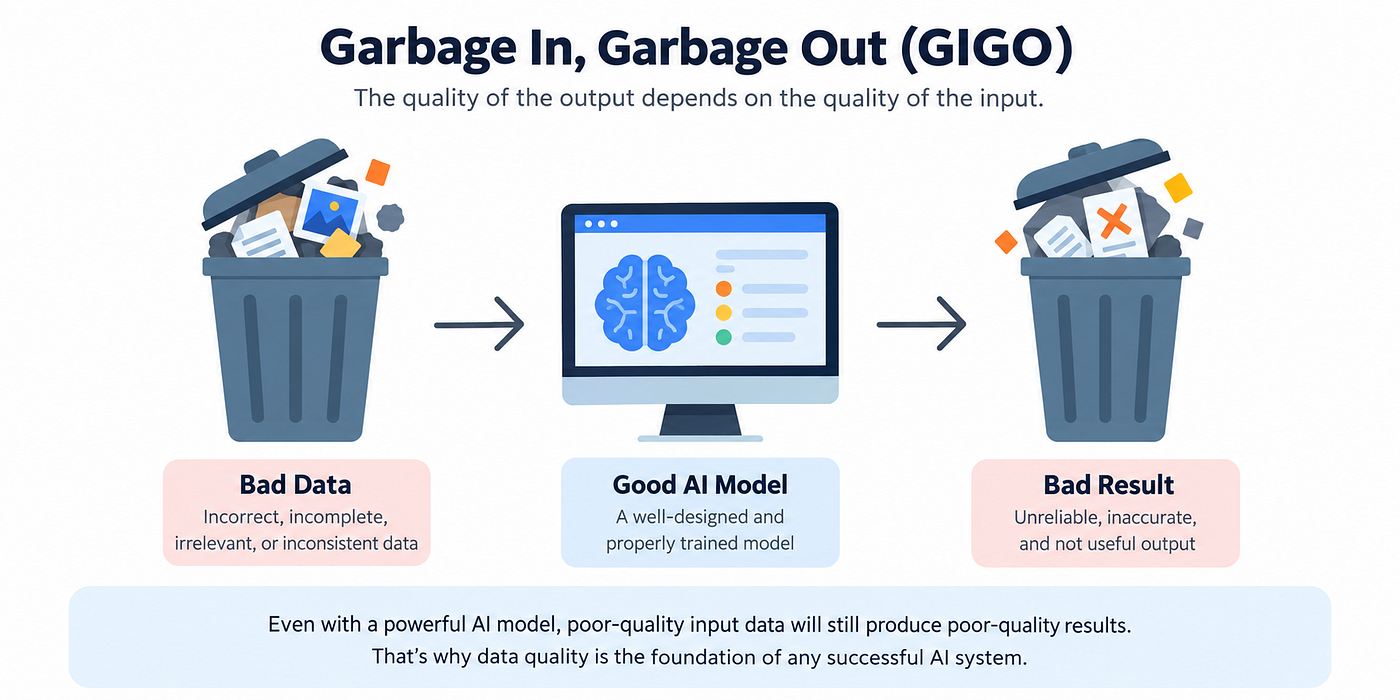

In [ ]:
# RUN THIS
print("=== How many of each outcome? (1 = cancer, 0 = no cancer) ===")
print(data["crc"].value_counts())
print(f"\nprevalence: {data['crc'].mean():.1%}")

print("\n=== Missing values ===")
missing = data.isna().sum()
print(missing[missing > 0])

print("\n=== Median value in each group ===")
display(
    data.groupby("crc")[["ctdna_vaf", "methyl_score", "cea_ng_ml", "days_to_colonoscopy"]]
        .median().round(4)
)

Look at that last table carefully.

`days_to_colonoscopy` separates the two groups far more cleanly than any assay
readout: a median of 15 days for cancers versus 45 for everyone else.

That is **not a discovery**. It is the care pathway responding to information the
model is not allowed to have. Remember it for Module 8.

Now a picture of the signal we **are** allowed to use.

In [ ]:
# RUN THIS
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

for ax, col, title in zip(axes,
                          ["ctdna_vaf", "methyl_score"],
                          ["ctDNA VAF (log scale)", "Methylation score"]):
    for label, name in [(0, "no cancer"), (1, "cancer")]:
        ax.hist(data.loc[data["crc"] == label, col], bins=25, alpha=0.6, label=name)
    ax.set_title(title)
    ax.set_xlabel(col)
    if col == "ctdna_vaf":
        ax.set_xscale("log")

axes[0].set_ylabel("number of patients")
axes[0].legend()
plt.tight_layout(); plt.show()

print("Look at the OVERLAP, not the shift. Plenty of cancers sit right inside")
print("the control distribution - those are the low shedders.")
print("This overlap sets a ceiling on performance that no algorithm can lift.")

**YOUR TURN 3**

Draw the same kind of histogram for a different column: `cea_ng_ml`.

**HINT:** copy the code below and change only the column name. You do not need
the log scale for CEA.

In [ ]:
# YOUR TURN
column_to_plot = None     # <-- replace None with "cea_ng_ml"  (keep the quotes)


# ---- this part draws it for you once you have set the name above ----
if column_to_plot is None:
    print("Not done yet. Replace None above with a column name in quotes.")
else:
    fig, ax = plt.subplots(figsize=(5, 3.4))
    for label, name in [(0, "no cancer"), (1, "cancer")]:
        ax.hist(data.loc[data["crc"] == label, column_to_plot].dropna(),
                bins=25, alpha=0.6, label=name)
    ax.set_xlabel(column_to_plot); ax.set_ylabel("patients"); ax.legend()
    plt.tight_layout(); plt.show()
    print("Overlapping again. No single marker separates these groups.")

<details>
<summary><b>Show the solution</b></summary>

```python
column_to_plot = "cea_ng_ml"
```

Try `"methyl_score"`, `"crp_mg_l"` or `"assay_qc_score"` too.

`assay_qc_score` is worth a look: the two histograms sit **exactly** on top of
each other, because that column is pure noise by construction. That is what "no
signal" looks like.

</details>

---
---
# MODULE 4 &mdash; Splitting the data

## 4.1 The idea

If you test a model on the same patients it learned from, you are measuring
**memory**, not **prediction**. The model has already seen the answers.

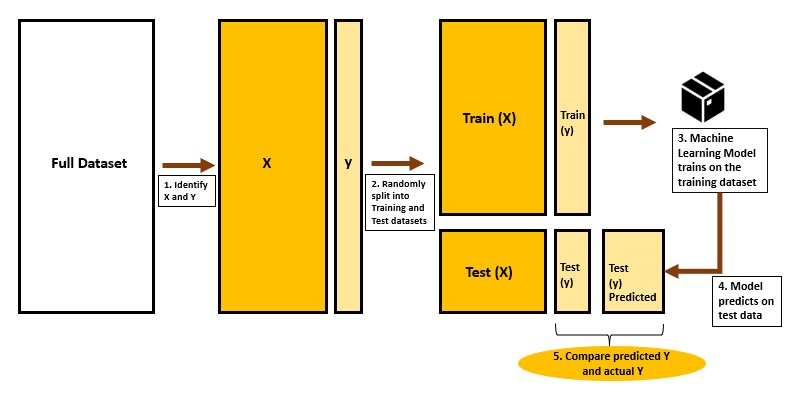

So we cut the data in two:

```
    ALL 240 PATIENTS
    |-------------------------------------------------|

    |---------------- 168 -----------------|--- 72 ---|
              TRAINING SET                   TEST SET
         the model learns from these        LOCKED AWAY
                                          opened once, at
                                              the end
```

**The rule for the rest of this notebook:** the test set is sealed. We do not
look at it, pick features with it, tune anything on it, or choose a model with
it. Every one of those turns an honest estimate into a flattering one.

## 4.2 Three choices to make on purpose

| Setting | What it does | Why |
|---|---|---|
| `test_size=0.30` | 30% held back | A compromise: bigger test set = more reliable estimate but less data to learn from |
| `stratify=y` | Same cancer proportion in both halves | With only 26% cases, chance alone could give you a lopsided test set |
| `random_state=42` | Same split every time | Reproducible. **Note what this does not mean:** it does not mean *stable* &mdash; see Module 6.3 |

In [ ]:
# RUN THIS
from sklearn.model_selection import train_test_split

# Pick the predictors EXPLICITLY. Never "everything except the outcome" -
# that is how the leak you did not think of gets in.
NUMERIC_FEATURES = [
    "age", "bmi",
    "ctdna_vaf", "cfdna_conc_ng_ml", "methyl_score", "fragment_ratio",
    "cea_ng_ml", "platelet_count", "crp_mg_l",
    "assay_qc_score", "sample_storage_months", "lab_tech_index",
]
CATEGORICAL_FEATURES = ["sex"]
TARGET = "crc"

# Deliberately left out:
#   patient_id          -> an identifier, carries no information
#   days_to_colonoscopy -> recorded AFTER the blood draw (Module 8)

X = data[NUMERIC_FEATURES + CATEGORICAL_FEATURES]     # the predictors
y = data[TARGET]                                      # the answer

assert TARGET not in X.columns, "The outcome must never be a predictor!"

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print(f"all patients : {len(X)}")
print(f"training set : {len(X_train)} patients, {int(y_train.sum())} cancers")
print(f"test set     : {len(X_test)} patients, {int(y_test.sum())} cancers")
print()
print(f"candidate predictors: {X.shape[1]}")
print(f"events per predictor: {y.sum() / X.shape[1]:.1f}   (rule of thumb says 10+)")
print()
print(f"Every performance number at the end rests on {int(y_test.sum())} cancers.")

**YOUR TURN 4**

The test set contains **19 cancers**.

Sensitivity is "of the cancers, what fraction did we catch?" &mdash; so with 19
cancers it can only move in steps of 1/19.

**Question:** would you report sensitivity to two decimal places?

Compute `1/19` below to see the step size.

**HINT:** `step = 1 / 19`

In [ ]:
# YOUR TURN

step = None          # <-- replace None with 1 / 19


# ---- check ----
if step is None:
    print("Not done yet. Replace None above.")
else:
    print(f"one patient changing class moves sensitivity by {step:.3f}")
    print(f"that is {step * 100:.1f} percentage points")
    print()
    print("So no - two decimal places claims a precision the data cannot support.")

<details>
<summary><b>Show the solution</b></summary>

```python
step = 1 / 19
```

One patient moving from "missed" to "caught" changes sensitivity by **5.3
percentage points**. Reporting "sensitivity 0.74" implies you know the third
significant figure of something estimated from 19 observations.

This is why Module 7 puts a confidence interval around everything.

</details>

---
---
# MODULE 5 &mdash; Missing values, and the most useful habit in this notebook

## 5.1 The idea

Two columns have gaps: `cea_ng_ml` (40 missing) and `crp_mg_l` (25). Most models
refuse to run with gaps, so you must decide what to do.

The simple option is **imputation**: fill each gap with a summary of that column
&mdash; here, the median.

The question that matters is **not** which value. It is **which data the value is
computed from**.

```
   WRONG                                RIGHT
   -----                                -----
   median of ALL 240 patients           median of the 168 TRAINING patients
            |                                     |
            v                                     v
   then split into train / test         then apply that same number to both

   The training data has secretly       The test set stays genuinely
   absorbed information from the        unseen.
   test patients.
```

The same applies to **scaling** (the mean and SD must come from training data
only), to **feature selection**, and to anything else that *learns a number*
from the data.

## 5.2 The habit: use a Pipeline

A scikit-learn **`Pipeline`** chains the preparation steps and the model into one
object.

- When you call `.fit()`, every step learns from the **training data only**
- When you call `.predict()`, the stored training values are applied
- Inside cross-validation, it re-learns them in every fold, automatically

This is how you stop having to remember the rule. **If you learn one practical
thing today, make it this.**

```
          Pipeline
   +---------------------------+
   |  1. fill gaps (median)    |   <- learned from training data
   |  2. put on a common scale |   <- learned from training data
   |  3. the model itself      |   <- learned from training data
   +---------------------------+
```

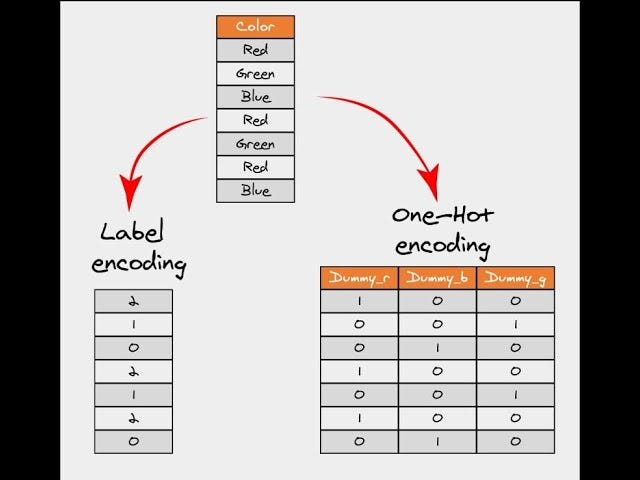

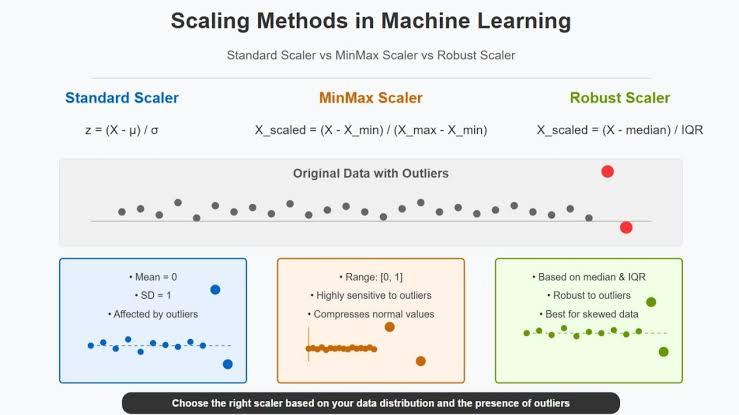
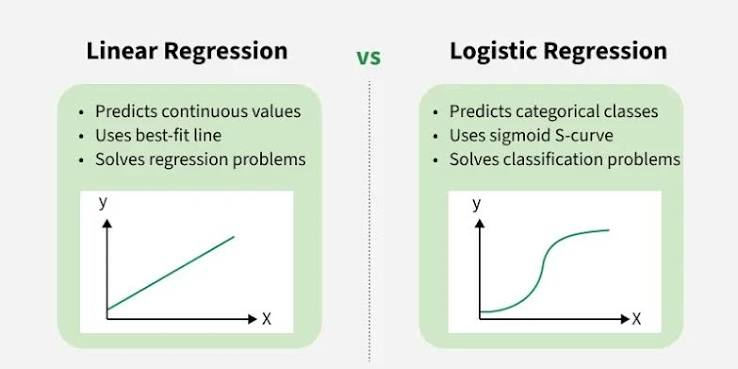

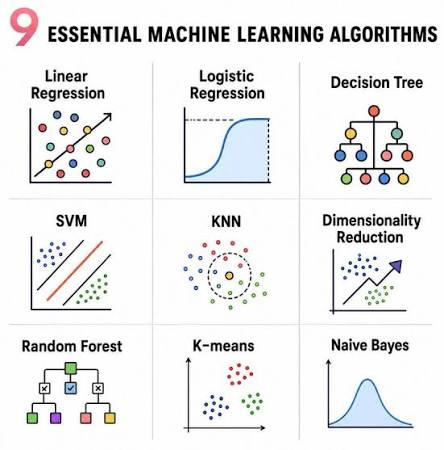

In [ ]:
# RUN THIS - builds the pipeline (it does not fit anything yet)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# numeric columns: fill gaps with the median, then put everything on one scale
numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])

# text columns ("F"/"M"): turn into numbers the model can use
categorical_steps = OneHotEncoder(handle_unknown="ignore", drop="if_binary")

preprocess = ColumnTransformer([
    ("num", numeric_steps,     NUMERIC_FEATURES),
    ("cat", categorical_steps, CATEGORICAL_FEATURES),
])

baseline_model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

print("Pipeline built. Nothing has been learned yet.")
baseline_model

## 5.3 Proof that it matters

Let us check that the pipeline really did learn the median from the training data
only &mdash; and that the "wrong" number is genuinely different.

In [ ]:
# RUN THIS (Important !!!!)
baseline_model.fit(X_train, y_train)      # <- this is where everything is learned

In [ ]:

# this is extra we may jump
learned = (baseline_model.named_steps["preprocess"]
           .named_transformers_["num"]
           .named_steps["impute"].statistics_)

train_median = float(learned[NUMERIC_FEATURES.index("cea_ng_ml")])
all_median   = float(data["cea_ng_ml"].median())

print(f"median of cea_ng_ml, TRAINING patients only : {train_median:.3f}   <- what the pipeline used")
print(f"median of cea_ng_ml, ALL patients           : {all_median:.3f}   <- leakage if you use this")
print()
print("Different numbers. Small difference here - but the same mistake with")
print("feature selection instead of imputation is catastrophic (Module 8).")

**YOUR TURN 5**

Find out what median the pipeline learned for **`crp_mg_l`** instead of
`cea_ng_ml`.

**HINT:** the only thing you need to change is the column name inside
`NUMERIC_FEATURES.index(...)`.

In [ ]:
# YOUR TURN

column_name = None     # <-- replace None with "crp_mg_l"  (keep the quotes)

# ---- check ----
if column_name is None:
    print("Not done yet. Replace None above.")
else:
    v = float(learned[NUMERIC_FEATURES.index(column_name)])
    print(f"median the pipeline learned for {column_name}: {v:.3f}")
    print(f"median across ALL patients:                 {float(data[column_name].median()):.3f}")

<details>
<summary><b>Show the solution</b></summary>

```python
column_name = "crp_mg_l"
```

</details>

---
---
# MODULE 6 &mdash; Your first model

## 6.1 Logistic regression

**Logistic regression** is the standard first model in clinical research. It
draws a boundary through the measurement space and asks which side of it a
patient falls on. It is fast, stable on small datasets, and every coefficient
means something you can report.

We already fitted it in the cell above. One line:

```python
baseline_model.fit(X_train, y_train)
```

That is genuinely all there is to it. **Everything hard about machine learning
happened before that line, and everything important happens after it.**

## 6.2 The first number &mdash; and why it is a trap

`.score()` gives **accuracy**: the fraction of test patients put in the right box.

Before you read it, work out what a model that learned **nothing** would score.
In a group that is 74% cancer-free, "always say no cancer" gets 0.74 without
looking at a single blood sample.

**That is the bar.**

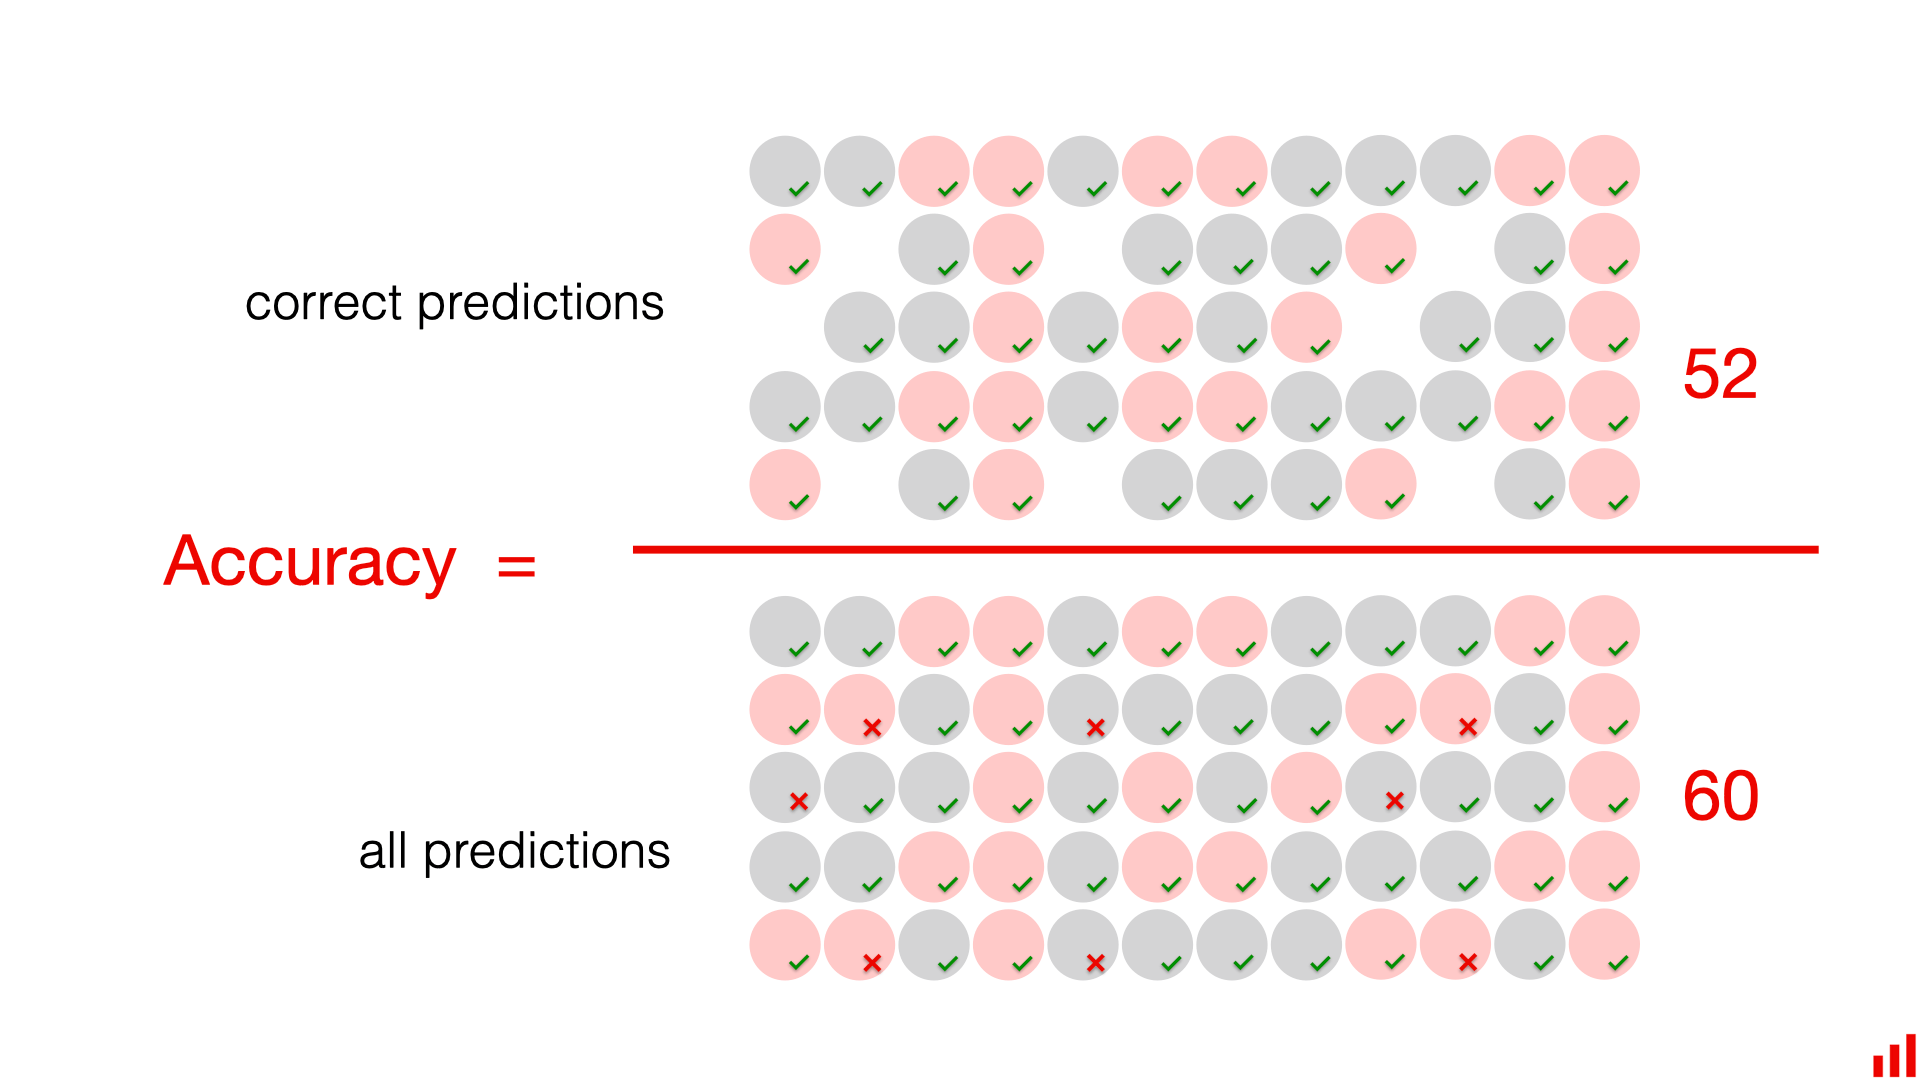

In [ ]:
# RUN THIS
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print(f"'always say no cancer'  accuracy : {dummy.score(X_test, y_test):.3f}")
print(f"logistic regression     accuracy : {baseline_model.score(X_test, y_test):.3f}")
print()
print("About ten points better than a model that does nothing at all.")
print("Is that good? Accuracy cannot tell you. Module 7 can.")

## 6.3 How stable is that number?

We evaluated on **one** split, chosen by `random_state=42`. Nothing about that
split is special.

So: run the identical workflow on ten different splits and look at the spread.
This takes a few seconds and it is the most sobering cell in the notebook.

In [ ]:
# RUN THIS
from sklearn.metrics import roc_auc_score

rows = []
for seed in range(1, 11):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=seed
    )
    # a FRESH pipeline each time - nothing carries over
    m = Pipeline([
        ("preprocess", ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale",  StandardScaler())]), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
                    CATEGORICAL_FEATURES),
        ])),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]).fit(X_tr, y_tr)

    rows.append({"split_seed": seed,
                 "test_auc": round(roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]), 3),
                 "test_accuracy": round(m.score(X_te, y_te), 3)})

spread = pd.DataFrame(rows)
display(spread)

print(f"lowest  AUC : {spread['test_auc'].min():.3f}")
print(f"highest AUC : {spread['test_auc'].max():.3f}")
print(f"SPREAD      : {spread['test_auc'].max() - spread['test_auc'].min():.3f}")

### Stop and look at that

Same data. Same model. Same code. **Nothing changed except an arbitrary number**
that decides who lands in which half.

The worst split gives **0.698**. The best gives **0.854**.

In an abstract, one of those is "limited discrimination" and the other is
"promising performance". They are the same model.

> If you had run this analysis once, got 0.854, and published it &mdash; nothing in
> the output would have warned you.

The fix is **not** "choose a better seed". It is: use cross-validation while
developing, put an interval around every number you report, and treat external
validation as compulsory. All three are coming.

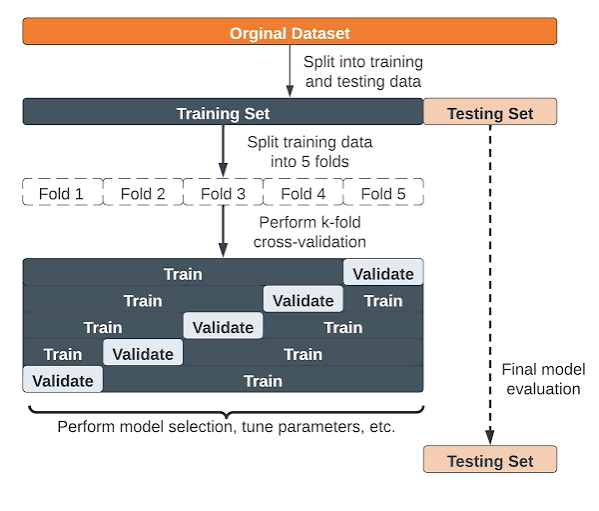


---
**YOUR TURN 6**

Compute how much better the **best** split looks compared with the **average**.

**HINT:** `spread["test_auc"].max() - spread["test_auc"].mean()`

In [ ]:
# YOUR TURN

optimism = None     # <-- replace None with your calculation


# ---- check ----
if optimism is None:
    print("Not done yet. Replace None above.")
else:
    print(f"Reporting only the best split overstates performance by {optimism:.3f} AUC.")
    print("And by 0.156 compared with the worst split.")
    print()
    print("Nothing was tuned. No features were selected. Just the split.")

<details>
<summary><b>Show the solution</b></summary>

```python
optimism = spread["test_auc"].max() - spread["test_auc"].mean()
```

About **0.07**. And that is before anyone starts trying different feature sets or
different models &mdash; each of which adds more opportunity to pick a winner by
chance.

</details>

---
---
# MODULE 7 &mdash; Is the model any good?

## 7.1 Say which class is "positive" first

Every number below depends on it. Get it wrong in a paper and the whole table is
wrong.

**Here: positive = `crc` = 1 = colorectal cancer.**

A **confusion matrix** is the four ways a prediction can land:

```
                        the model said
                    no cancer      cancer
                  +------------+------------+
   truly       no |     TN     |     FP     |   FP = unnecessary colonoscopy
   no cancer      |            |            |
                  +------------+------------+
   truly          |     FN     |     TP     |
   cancer         |  *MISSED   |            |
                  |   CANCER*  |            |
                  +------------+------------+
```

Those four cells have wildly different costs. A false positive is an unnecessary
procedure. A false negative is a missed cancer.

**Accuracy weights them identically.** That is the first reason it misleads.

# **Function Predict vs predict-proba**

1. Hard Decisions: predict()

`y_pred = baseline_model.predict(X_test)                # the 0/1 decisions`
The .predict() method forces the model to make a final, black-and-white decision.

It outputs an array of discrete labels, like [0, 0, 1, 0, 1].

In this context, 0 usually means "No Cancer" and 1 means "Cancer".

By default, if the model is more than 50% sure it's cancer, it predicts 1. If it's less than 50% sure, it predicts 0.

2. Confidence Scores: predict_proba()

`y_prob = baseline_model.predict_proba(X_test)[:, 1]    # the probability of cancer`
The .predict_proba() method asks the model to reveal its underlying math—how confident it is in its prediction, returning values between 0.0 and 1.0.

Here is why the [:, 1] part is necessary at the end:

In [ ]:
# RUN THIS
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = baseline_model.predict(X_test)                # the 0/1 decisions
y_prob = baseline_model.predict_proba(X_test)[:, 1]    # the probability of cancer

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay(cm, display_labels=["no cancer", "cancer"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Test set, default threshold 0.5")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn:3d}   correctly left alone")
print(f"FP = {fp:3d}   unnecessary colonoscopy")
print(f"FN = {fn:3d}   *** MISSED CANCER ***")
print(f"TP = {tp:3d}   cancer correctly flagged")
print()
print(f"Of the {tp + fn} cancers in the test set, we caught {tp} and missed {fn}.")

### Read that last line again

This is the **same model** we just called 83% accurate.

It misses **11 of the 19 cancers**. More than half.

> A model can be right about 83% of patients and still miss most of the cancers,
> and accuracy will never tell you that.

That one sentence is why this module exists.

## 7.2 The four numbers that actually describe it

$$\text{sensitivity} = \frac{TP}{TP + FN} \qquad\qquad
  \text{specificity} = \frac{TN}{TN + FP}$$

- **Sensitivity** &mdash; of the people **with** cancer, what fraction did we flag?
- **Specificity** &mdash; of the people **without**, what fraction did we leave alone?

Neither depends on how common the disease is.

$$\text{PPV} = \frac{TP}{TP + FP} \qquad\qquad \text{NPV} = \frac{TN}{TN + FN}$$

- **PPV** &mdash; if the model says cancer, how often is it right?
- **NPV** &mdash; if it says no cancer, how often is it right?

**These two depend heavily on prevalence** &mdash; and that is the trap that kills
screening claims. Our clinic is 26% cancer because it is a symptomatic referral
population. Move the identical model to population screening at 0.3% and watch
what happens.

In [ ]:
# RUN THIS
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"accuracy    {(tp + tn) / cm.sum():.3f}")
print(f"sensitivity {sensitivity:.3f}   <- of {tp + fn} cancers, {tp} flagged")
print(f"specificity {specificity:.3f}")
print(f"PPV         {tp / (tp + fp):.3f}   at this clinic's {y_test.mean():.0%} prevalence")
print(f"NPV         {tn / (tn + fn):.3f}")

print("\nSAME model, SAME sensitivity and specificity, different populations:")
for prevalence, where in [(0.26, "symptomatic clinic"),
                          (0.05, "high-risk screening"),
                          (0.003, "population screening")]:
    ppv = (sensitivity * prevalence) / (
        sensitivity * prevalence + (1 - specificity) * (1 - prevalence))
    print(f"   prevalence {prevalence:>6.1%}  ({where:<20s}) -> PPV = {ppv:.3f}")

print("\nAt population prevalence, 94 out of every 100 positives would be wrong.")

## 7.3 The threshold is your decision, not the model's

The model does not really output 0 or 1. It outputs a **probability**, and
`.predict()` applies a cut-off of **0.5** to it.

That 0.5 is a software default. It is not a property of the model, and it is
almost never the right clinical choice.

> **The threshold is where you decide how many unnecessary colonoscopies one
> missed cancer is worth.** That is a clinical judgement, not a statistical one.

Lower the threshold and you catch more cancers and scope more healthy people.
Raise it and the reverse.

In [ ]:
# RUN THIS
print(f"{'threshold':>10s}{'sensitivity':>13s}{'specificity':>13s}{'missed':>9s}{'extra scopes':>14s}")
print("-" * 60)
for t in [0.50, 0.40, 0.30, 0.20, 0.10]:
    c = confusion_matrix(y_test, (y_prob >= t).astype(int), labels=[0, 1])
    a, b, cc, d = c.ravel()
    print(f"{t:>10.2f}{d/(d+cc):>13.2f}{a/(a+b):>13.2f}{cc:>9d}{b:>14d}")

print()
print("For a TRIAGE tool, the default 0.5 is clearly the wrong choice -")
print("it saves one colonoscopy at the cost of missing 11 cancers.")
print()
print("Important: choose the threshold on TRAINING data, never on the test set.")

## 7.4 ROC and AUC &mdash; all thresholds at once

The **ROC curve** plots sensitivity against (1 &minus; specificity) for every
possible threshold. **ROC-AUC** is the area under it, and it has one clean
meaning:

> Take one random patient **with** cancer and one **without**. The AUC is the
> probability that the model gives the higher risk score to the one with cancer.

- **0.5** = a coin flip
- **1.0** = perfect separation

AUC is **threshold-free**. That is its strength (it summarises *ranking*, which
is exactly what a triage tool needs) and its weakness (it says nothing about
whether any usable threshold exists, and nothing about whether the probabilities
are calibrated).

In [ ]:
# RUN THIS
from sklearn.metrics import roc_curve, RocCurveDisplay

fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc).plot(ax=ax, name="our model")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.scatter(1 - specificity, sensitivity, s=70, zorder=5, color="crimson",
           label="default threshold 0.5")
ax.set_title("ROC curve")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"ROC-AUC = {auc:.3f}")
print()
print("Note where the red dot sits: far to the left, high specificity,")
print("low sensitivity. The curve is fine; the THRESHOLD is the problem.")

## 7.5 How uncertain is that AUC?

### The problem

We measured AUC = 0.790. But we measured it on **72 particular patients**, only
19 of whom had cancer.

If a different 72 patients had ended up in the test set, we would have got a
different number. How different? That matters a lot:

- "0.790, and it could easily have been 0.75 to 0.83" is a useful result
- "0.790, and it could easily have been 0.65 to 0.92" is a much weaker claim

We cannot answer this directly, because we only have one test set.

### The bootstrap

A **bootstrap** is a way of getting an uncertainty estimate out of the single
sample you already have.

Imagine a bag holding 72 cards, one for each test patient:

1. Pull out a card, write down which patient it is, and **put it back**
2. Repeat 72 times
3. You now have a new group of 72 &mdash; but not the same 72. Some patients were
   drawn two or three times, others not at all
4. Calculate the AUC for this new group
5. Do all of that 2,000 times

The result is 2,000 slightly different AUC values. **How much they vary tells us
how much our AUC would move if we had recruited different people.**

Putting the card back each time is what makes the groups different. This is what
"resample **with replacement**" means.

### What to expect

The cell below gives roughly:

> **AUC 0.790, 95% interval 0.646 to 0.915**

Read that as: *the data are consistent with the true performance being anywhere
between about 0.65 and about 0.92.*

That is a very wide range. It is also the honest one.

### Three things a bootstrap does not do

- **It only covers one kind of uncertainty:** which patients are in the test set.
  It does **not** include the variation from the split itself, which you measured
  in Module 6.3 and which was a further 0.156. The real uncertainty is wider than
  this interval suggests.
- **With only 19 cancers, the interval is itself rough.** Some resampled groups
  contain just 10 or 12 cancers.
- **It measures precision, not correctness.** A model with a leak in it will give
  you a narrow confidence interval around a completely wrong number. A bootstrap
  will never warn you about anything in Module 8.

In [ ]:
# RUN THIS
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = []

for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if len(np.unique(y_arr[idx])) < 2:        # need both classes present
        continue
    boot.append(roc_auc_score(y_arr[idx], y_prob[idx]))

boot = np.array(boot)
lo, hi = np.percentile(boot, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(5.2, 3))
ax.hist(boot, bins=40, color="steelblue", alpha=0.8)
ax.axvline(auc, color="crimson", lw=2, label=f"our estimate {auc:.3f}")
ax.axvline(lo, color="k", ls="--", lw=1)
ax.axvline(hi, color="k", ls="--", lw=1, label=f"95% CI {lo:.2f}-{hi:.2f}")
ax.set_xlabel("ROC-AUC"); ax.set_ylabel("count"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"ROC-AUC {auc:.3f}, 95% confidence interval [{lo:.3f}, {hi:.3f}]")
print(f"interval width: {hi - lo:.3f}")

**YOUR TURN 7**

A competing assay published an AUC of **0.86** in a different cohort.

On this evidence, is our model better, worse, or indistinguishable?

**HINT:** is 0.86 inside our confidence interval? Compare it with `lo` and `hi`.

In [ ]:
# YOUR TURN
competitor_auc = 0.86

inside = None     # <-- replace None with:  (competitor_auc > lo) and (competitor_auc < hi)


# ---- check ----
if inside is None:
    print("Not done yet. Replace None above.")
else:
    print(f"our interval: {lo:.3f} to {hi:.3f}")
    print(f"competitor  : {competitor_auc}")
    print(f"inside our interval? {inside}")
    print()
    if inside:
        print("So: INDISTINGUISHABLE. We have no evidence either is better.")
    else:
        print("Check your comparison - 0.86 should fall inside.")

<details>
<summary><b>Show the solution and the two caveats</b></summary>

```python
inside = (competitor_auc > lo) and (competitor_auc < hi)
```

**Indistinguishable.** 0.86 sits comfortably inside our interval, so there is no
basis for claiming either assay is better.

Two things worth knowing, because reviewers ask:

1. This bootstrap interval only covers **sampling variation in the test set**. It
   does **not** include the variation from the split choice that you measured in
   Module 6.3 &mdash; a further 0.156. The true uncertainty is wider than the
   interval suggests.
2. Comparing AUCs **across different cohorts** is not a like-for-like comparison
   at all, however the intervals behave. Different disease spectrum, different
   prevalence, different assay conditions.

**The honest summary of our result:** "AUC 0.790, 95% CI 0.65&ndash;0.92, in this
cohort, on this split." Both that and the bare "0.790" are true. Only one is
reportable.

</details>

## 7.6 What to report &mdash; the minimum honest set

- the **confusion matrix**, with the positive class stated
- **sensitivity and specificity** at the threshold you propose, *with the
  threshold named*
- **ROC-AUC**, as the threshold-free summary
- **PPV and NPV**, with the prevalence they assume stated explicitly
- an **interval** around each number
- a **comparison**: a majority-class baseline at minimum, and ideally current
  clinical practice. A model that does not beat current practice is not a result.

**And one thing none of these establishes: clinical utility.** Sensitivity,
specificity and AUC describe *discrimination on a retrospective dataset*. Whether
a model actually improves patient outcomes is a question about calibration,
decision thresholds, workflow and cost &mdash; answered by decision-curve analysis
and ultimately a prospective study. Not by anything in this notebook.

---
---
# MODULE 8 &mdash; Four ways to fool yourself

These are not exotic mistakes made by careless people. They are the normal
failure modes of this literature, and at least one of them is probably in a paper
you have cited.

## 8.1 Leakage, form A: a variable from the future

> **Leakage** is any situation where the model sees, during training,
> information it would not have at the moment of prediction.

The signature is always the same: **performance that is too good, and no error
message.** Nothing crashes. Nothing warns you.

```
   TIMELINE
   ========

   blood draw                              colonoscopy result
   (prediction time)                       (outcome known)
        |                                        |
        |----------------------------------------|
        |                                        |
   [ what the model                          days_to_colonoscopy
     is allowed                              recorded HERE
     to use ]                                     |
        ^                                         |
        |_________________________________________|
                  leaked backwards into training
```

Let us do it deliberately.

In [ ]:
# RUN THIS - the mistake, on purpose
LEAKY_FEATURES = NUMERIC_FEATURES + ["days_to_colonoscopy"]

X_leaky = data[LEAKY_FEATURES + CATEGORICAL_FEATURES]
X_tr_l, X_te_l, y_tr_l, y_te_l = train_test_split(
    X_leaky, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

leaky_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale",  StandardScaler())]), LEAKY_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
                CATEGORICAL_FEATURES),
    ])),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_tr_l, y_tr_l)

leaky_auc = roc_auc_score(y_te_l, leaky_model.predict_proba(X_te_l)[:, 1])

print(f"honest model                     ROC-AUC = {auc:.3f}")
print(f"with days_to_colonoscopy added   ROC-AUC = {leaky_auc:.3f}")
print()
print("Note it is NOT a suspicious 1.000 - it is a plausible, excellent 0.967.")
print("That is what makes leakage hard to spot: it looks like a good result,")
print("not like a bug. The code is correct. The STUDY is wrong.")

**YOUR TURN 8.1**

Apply the test to your own work.

> *Could I have written this value down on the day the sample was taken, without
> knowing what happened afterwards?*

Name one variable in **your** dataset that fails it. If you cannot think of one,
name the one you are least sure about.

<details>
<summary><b>Show the ones that catch people most often</b></summary>

- treatment started, regimen, line of therapy
- referral urgency, time-to-procedure, time-to-result, MDT discussion flag
- repeat samples or follow-up assay results
- a pathology or staging variable used to "predict" diagnosis
- **sample batch or plate**, when cases and controls were processed separately
- **collection site or hospital**, when recruitment differed between groups
- freezer time or storage duration, if it differs systematically by group

The last three are the subtle ones, and the most relevant to liquid-biopsy work.
If all your cases ran in batch 1 and all your controls in batch 2, the model can
learn **the batch** and report excellent performance on a purely technical
signal. It is not information from the future, but it is still information about
group membership that is not information about biology.

**The defence is process, not cleverness:** write your predictor list *before*
you open the data, with a time point attached to each variable, and have somebody
who did not assemble the cohort challenge it.

</details>

## 8.2 Leakage, form B: feature selection before splitting

This one is subtler, far more common, and much more damaging.

The tempting workflow, which appears in a great deal of published biomarker work:

1. Measure 4,000 features on 120 samples
2. Correlate each feature with the outcome **across all the data**
3. Keep the best 20
4. Cross-validate a model on those 20
5. Report a beautiful AUC

**Step 2 used the outcome of every sample**, including the ones later used for
validation. The selection has already seen the answers. The cross-validation in
step 4 is cosmetic &mdash; the damage was done before it started.

To show how badly this fails, the next cell uses data with **no signal
whatsoever**: 4,000 columns of random numbers and a coin-flip outcome. The true
AUC is 0.5 by construction. Anything above that is manufactured by the procedure.

In [ ]:
# RUN THIS
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif

noise_rng = np.random.default_rng(0)
X_noise = noise_rng.normal(size=(120, 4000))    # 4000 columns of PURE NOISE
y_noise = noise_rng.integers(0, 2, 120)         # a coin flip
# TRUE AUC = 0.500. There is nothing to find.

cv = StratifiedKFold(5, shuffle=True, random_state=0)

# --- THE WRONG WAY: pick features using ALL the data, then cross-validate
corr = np.abs([np.corrcoef(X_noise[:, j], y_noise)[0, 1] for j in range(4000)])
best20 = np.argsort(corr)[-20:]
auc_wrong = cross_val_score(LogisticRegression(max_iter=1000),
                            X_noise[:, best20], y_noise,
                            cv=cv, scoring="roc_auc").mean()

# --- THE RIGHT WAY: selection INSIDE the pipeline, redone in every fold
auc_right = cross_val_score(
    Pipeline([("select", SelectKBest(f_classif, k=20)),
              ("clf",    LogisticRegression(max_iter=1000))]),
    X_noise, y_noise, cv=cv, scoring="roc_auc").mean()

print("The data contains NO signal at all. True AUC = 0.500")
print("-" * 58)
print(f"selection BEFORE splitting   (wrong)  CV AUC = {auc_wrong:.3f}")
print(f"selection INSIDE the pipeline (right) CV AUC = {auc_right:.3f}")
print()
print("0.940 out of random numbers. Nothing in the output warns you.")

### Scale that to your own work

4,000 features is a modest methylation panel. 120 samples is a generous
liquid-biopsy cohort. This is not a toy example &mdash; it is a documented cause of
a large body of irreproducible high-dimensional biomarker literature.

> **The rule:** every step that looks at the **outcome** &mdash; feature selection,
> threshold choice, normalisation parameters, batch correction &mdash; belongs
> *inside* the resampling loop. If you cannot put it inside a `Pipeline`, that is
> a warning sign, not an inconvenience.

**One useful distinction:** filtering that uses only the *features* (variance,
detection rate, missingness) is fine outside the loop. Filtering that uses the
*outcome* is not.

## 8.3 Class imbalance

Because only 26% of the patients in this dataset have cancer, the data is heavily skewed. This causes two major issues:

* **Accuracy is a trap:** If a model simply guesses "Healthy" for every single patient, it achieves 73.6% accuracy without actually learning anything.
* **The model plays it safe:** By default, the model needs to be >50% sure to predict cancer. Because cancer is rare, it hesitates. It misses a lot of actual cancers (low sensitivity) but correctly identifies almost all healthy patients (high specificity).

## How to Fix It

**Good Solutions:**

* **Stratified splitting:** Ensure your training and testing sets both maintain that exact 26% ratio.
* **Use better metrics:** Ignore overall accuracy and look at metrics that measure how well you catch the rare cases (like AUC).
* **Move the threshold:** Lower the 50% decision cutoff so the model flags cancer more easily.
* **Penalize mistakes:** Use `class_weight="balanced"` in your code to force the model to care more about getting the rare cancer cases right.

**Overrated Solutions (What to Avoid):**

* **Synthetic Data (SMOTE):** Generating fake data to balance the classes is very popular but highly overrated. Researchers frequently apply it incorrectly (causing data leakage), and it rarely performs better than simply lowering your decision threshold.

In [ ]:
# RUN THIS
balanced_model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced",
                                      random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

cb = confusion_matrix(y_test, balanced_model.predict(X_test), labels=[0, 1])
a, b, c, d = cb.ravel()

print(f"{'':24s}{'accuracy':>10s}{'sens':>8s}{'spec':>8s}{'missed':>9s}{'AUC':>8s}")
print("-" * 67)
print(f"{'default':24s}{(tp+tn)/cm.sum():>10.3f}{sensitivity:>8.2f}{specificity:>8.2f}"
      f"{fn:>9d}{auc:>8.3f}")
print(f"{'class_weight=balanced':24s}{(d+a)/cb.sum():>10.3f}{d/(d+c):>8.2f}{a/(a+b):>8.2f}"
      f"{c:>9d}"
      f"{roc_auc_score(y_test, balanced_model.predict_proba(X_test)[:, 1]):>8.3f}")
print()
print("Accuracy went DOWN. Missed cancers went DOWN from 11 to 6. AUC barely moved.")
print("Which of those three numbers matters depends entirely on the intended use.")

## 8.4 Overfitting

A model **overfits** when it learns the noise in the training data as if it were
signal. It shows up as a **big gap between training and test performance**.

```
   GOOD                           OVERFIT
   ----                           -------
   train AUC  0.86                train AUC  1.00   <- perfect!
   test  AUC  0.79                test  AUC  0.62   <- useless
   gap        0.07                gap        0.38
```

Below: a decision tree with no limits, which has enough flexibility to memorise
all 168 training patients exactly.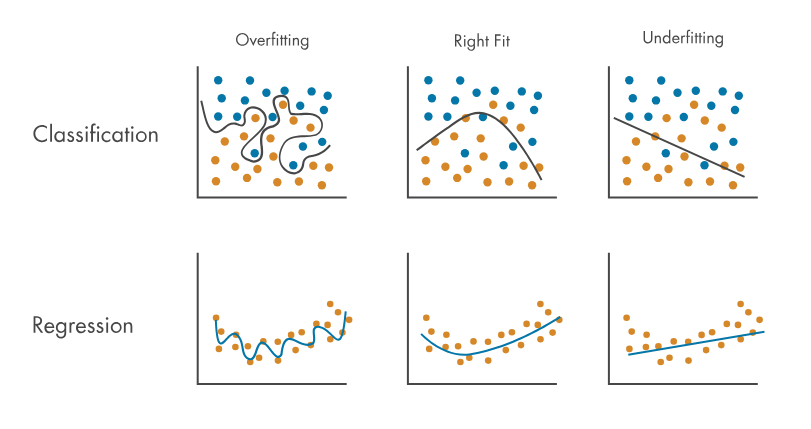

In [ ]:
# RUN THIS
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),   # no depth limit
]).fit(X_train, y_train)

rows = []
for name, mdl in [("logistic regression", baseline_model),
                  ("unconstrained decision tree", tree_model)]:
    rows.append({"model": name,
                 "train AUC": round(roc_auc_score(y_train, mdl.predict_proba(X_train)[:, 1]), 3),
                 "test AUC":  round(roc_auc_score(y_test,  mdl.predict_proba(X_test)[:, 1]), 3)})

gap = pd.DataFrame(rows)
gap["gap"] = (gap["train AUC"] - gap["test AUC"]).round(3)
display(gap)

print("A perfect training score is not an achievement. It is a symptom.")
print("Always report BOTH numbers. A paper showing only one is hiding the gap.")

## 8.5 Cross-validation, and what the test set is for

A single split gives one estimate from one small test set. You saw in Module 6.3
how unstable that is.

**Cross-validation** uses the training data more efficiently: cut it into *k*
folds, train on *k*&minus;1, validate on the one left out, rotate, average.

```
   TRAINING DATA split into 5 folds        TEST SET
   +----+----+----+----+----+              +--------+
   | V  | f  | f  | f  | f  |              |        |
   | f  | V  | f  | f  | f  |              | LOCKED |
   | f  | f  | V  | f  | f  |              |        |
   | f  | f  | f  | V  | f  |              | opened |
   | f  | f  | f  | f  | V  |              |  ONCE  |
   +----+----+----+----+----+              +--------+
    V = validate   f = fit
```

| | Used for | How often you may touch it |
|---|---|---|
| **Cross-validation** (training data) | Comparing models, tuning, feature selection, choosing a threshold | As often as you like |
| **Test set** | One final, unbiased estimate | **Once**, at the very end |
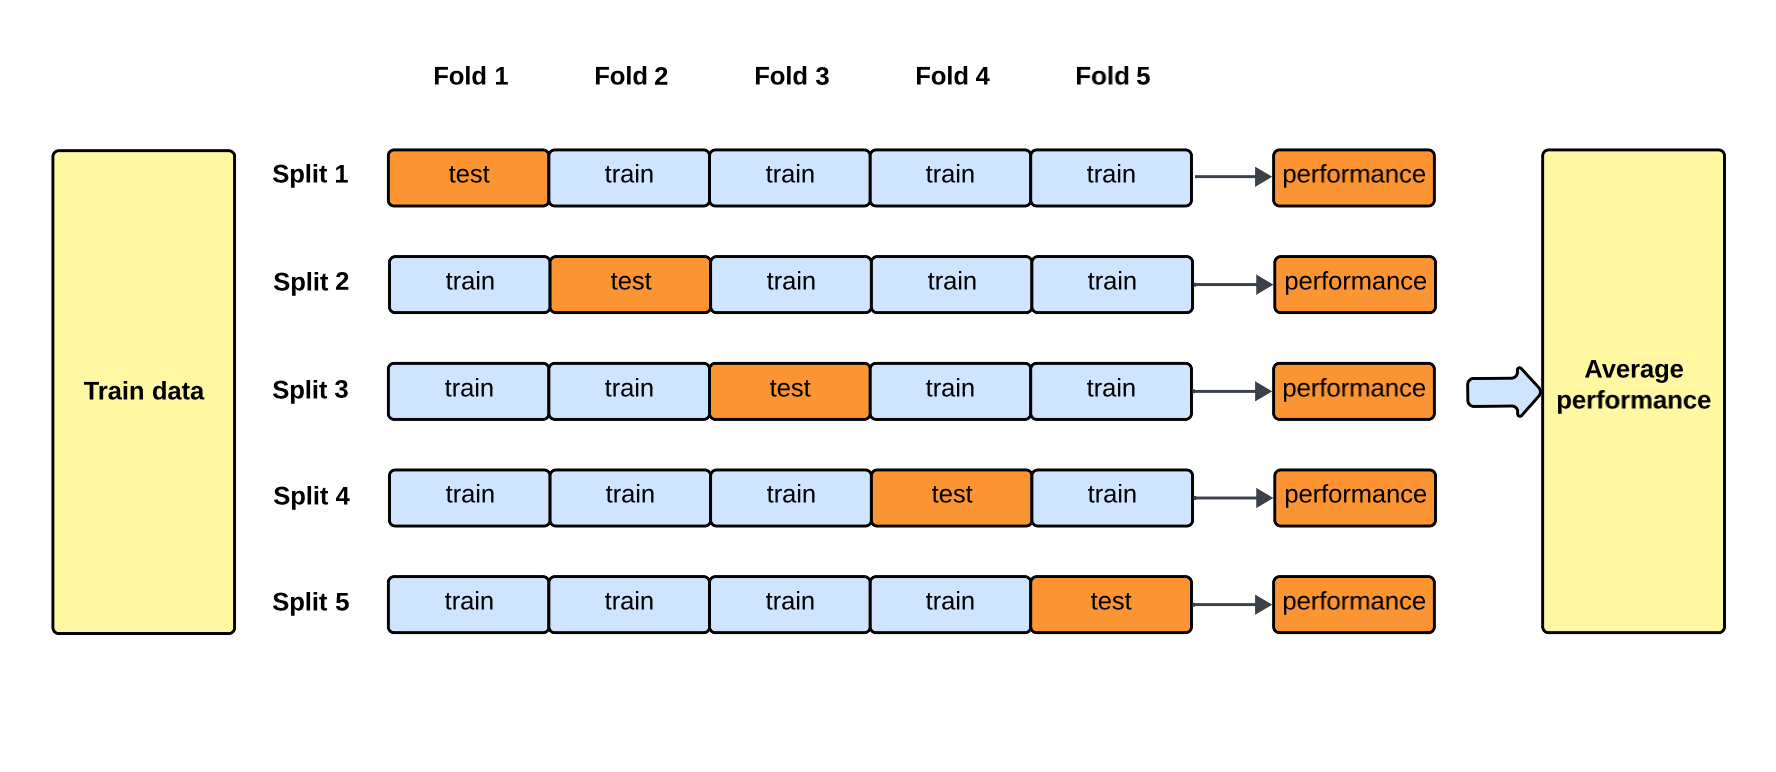
The moment you choose anything based on the test set, it stops being a test set
and becomes part of your training procedure &mdash; and your reported performance
becomes optimistic by an unknown amount.

In [ ]:
# RUN THIS
cv_scores = cross_val_score(
    baseline_model, X_train, y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc")

print("5-fold cross-validation, TRAINING data only")
print("fold AUCs:", np.round(cv_scores, 3))
print(f"mean {cv_scores.mean():.3f}  (SD {cv_scores.std():.3f})")
print()
print(f"single held-out test AUC: {auc:.3f}")
print()
print("The means agree well. But look at the INDIVIDUAL FOLDS: the same model,")
print("the same data, scoring from 0.73 to 0.91 depending on which ~34 patients")
print("happened to land in the validation fold.")
print()
print("No single number here is 'the' performance. That is the honest summary")
print("of a dataset this size.")

## 8.6 External validation &mdash; the one nobody can skip

Everything above is **internal** validation: one cohort, cut in two. It answers
*"does this work on patients like the ones I already have?"*

It does **not** answer *"does this work anywhere else?"*

That needs an **external** cohort: a different site, a different time period, a
different assay run, ideally a different population.

Performance almost always drops. The usual causes:

- **case mix** differs &mdash; different disease spectrum or stage distribution
- **prevalence** differs &mdash; PPV and NPV move even when the model does not
- **assay and pre-analytics** differ &mdash; tubes, processing delay, depth, batch
- **the care pathway** differs &mdash; which changes what recorded variables *mean*

> **Say this plainly in your own papers:** a single train/test split, as used
> throughout this notebook, is a teaching simplification. It is not a clinical
> validation. A model intended for clinical use requires, at minimum, external
> validation in an independent cohort, an assessment of calibration (not just
> discrimination), and a prospective evaluation of whether using it changes
> patient outcomes.

---
---
# MODULE 9 &mdash; Final project: build it yourself

Time to put the whole thing together without the scaffolding.

## The task

A collaborator sends you a **new cohort of 400 patients**, collected at a
different hospital. Same measurements.

**Your job:** does the model we built still work on them?

This is the external-validation question from Module 8.6, and it is the single
most informative experiment you can run on a prediction model.

### What you need to do

1. Generate the new cohort (code given &mdash; just run it)
2. Apply the **already-trained** model to it &mdash; do **not** retrain
3. Compute the AUC on the new cohort
4. Compare with the 0.790 we got on the original test set

### Step 1 &mdash; the new cohort (run this)

In [ ]:
# RUN THIS - a "different hospital" cohort
# Note random_state=7, so these are different patients from a different draw
external = make_colomark_data(n=400, random_state=7)

print("external cohort:", external.shape)
print("prevalence:", f"{external['crc'].mean():.1%}")
external.head(3)

### Step 2 &mdash; your turn

Now **you** write the validation. Three lines.

**HINT:** you need to
1. pull the predictor columns out of `external` &mdash; the same columns as `X`
   (`NUMERIC_FEATURES + CATEGORICAL_FEATURES`)
2. pull the outcome column out (`"crc"`)
3. get predicted probabilities with
   `baseline_model.predict_proba(...)[:, 1]` and score them with
   `roc_auc_score(...)`

**Do not call `.fit()`.** The whole point is to apply the model you already have.

If this feels like too much, use the **ASK AN AI** box underneath.

In [ ]:
# YOUR TURN - external validation

X_external = None       # <-- the predictor columns of `external`
y_external = None       # <-- the "crc" column of `external`
external_auc = None     # <-- the AUC of baseline_model on this cohort


# ---- check ----
if external_auc is None:
    print("Not done yet. Fill in the three lines above.")
    print("Stuck? Use the ASK AN AI prompt below, or open the solution.")
else:
    print(f"original test cohort  AUC = {auc:.3f}")
    print(f"external cohort       AUC = {external_auc:.3f}")
    print(f"difference                = {external_auc - auc:+.3f}")

### ASK AN AI

If you are stuck, paste this into ChatGPT, Claude or Gemini, then paste the code
it gives you into the cell above (replacing the three `None` lines) and run it.

```
I have a trained scikit-learn Pipeline called `baseline_model` that predicts a
binary outcome.

I have a new pandas DataFrame called `external` with the same columns as my
training data. The predictor column names are in two Python lists called
NUMERIC_FEATURES and CATEGORICAL_FEATURES. The outcome column is called "crc".

Write three lines of Python that:
1. select the predictor columns from `external` into X_external
2. select the "crc" column into y_external
3. compute the ROC-AUC of baseline_model on this new data, into external_auc,
   using predicted probabilities and sklearn's roc_auc_score

Do NOT retrain the model - I want to apply the existing fitted pipeline.
Return only the three lines of code, no explanation.
```

**Then check what it gave you.** Three questions, every time you use AI for code:

1. Does it call `.fit()` anywhere? **If yes, it is wrong** &mdash; that would retrain
   the model and defeat the entire purpose.
2. Does it use `predict_proba(...)[:, 1]` rather than `predict(...)`? AUC needs
   probabilities, not 0/1 decisions. Using `predict()` gives a different, lower
   number that is not the AUC you want.
3. Does it select columns explicitly, or does it do something like
   `external.drop(columns=["crc"])`? The second version would quietly include
   `patient_id` and `days_to_colonoscopy` &mdash; **the leak from Module 8**.

> Point 3 is the real lesson of this exercise. An AI will happily hand you
> leakage, confidently and in well-formatted code, because it does not know which
> of your columns are recorded after the outcome. **You do.** That judgement is
> the part of your job that does not get automated.

<details>
<summary><b>Show the solution</b></summary>

```python
X_external = external[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y_external = external["crc"]
external_auc = roc_auc_score(y_external, baseline_model.predict_proba(X_external)[:, 1])
```

**What you should see:** **AUC 0.827**, against 0.790 on the original test set.

Note that it came out *higher*. That is not the model improving &mdash; it is the
same wobble you measured in Module 6.3, now showing up between cohorts. A
difference of +0.04 here means nothing at all.

**And here is the catch.** This "external" cohort is not really external. It came
from the **same generator**, with the same assumptions, the same effect sizes and
the same noise structure. The only thing that changed was the random seed.

So this experiment shows the best case that external validation could possibly
give you: *no distribution shift at all*. A real external cohort has a different
case mix, a different assay protocol, a different batch structure and a different
care pathway &mdash; and performance usually drops, often a lot.

**If a simulation cannot be more pessimistic than reality, it should not be used
to reassure you.** Treat this number as a sanity check that your code is correct,
never as evidence that the model generalises.

</details>

### Optional extension &mdash; if you want to go further

Try one of these. Each takes a few minutes, and each has an **ASK AN AI** prompt
you can adapt.

**A. Which measurements did the model actually rely on?**

```
I have a fitted scikit-learn Pipeline called `baseline_model`. Its last step is
named "classifier" and is a LogisticRegression. Its first step is a
ColumnTransformer named "preprocess".

Write Python that extracts the fitted coefficients and shows them next to the
correct feature names, sorted by absolute size, as a pandas DataFrame.
```

Then ask yourself the harder question: **do large coefficients mean those markers
are biologically important?** (They do not. See Module 2.1. And the three pure-
noise columns are still in the model &mdash; check where they ended up.)

**B. Does a more complicated model do better?**

```
Using scikit-learn, show me how to swap the LogisticRegression in an existing
Pipeline for a RandomForestClassifier, keeping the same preprocessing steps, and
compare 5-fold cross-validated ROC-AUC between the two on the same training data.
```

Expect the answer to be "not really, and sometimes worse". With 168 training
patients and 13 features, a more flexible model has more ways to overfit and
nothing extra to learn.

**C. Deliberately break something.**

Add `days_to_colonoscopy` back in, or impute the median before splitting instead
of inside the pipeline, and measure how much the AUC inflates. Breaking things on
purpose, in a setting where you know the right answer, is the fastest way to
learn to recognise it in somebody else's paper.

---
---
# MODULE 10 &mdash; Review a study

No code. Read this as if you were the reviewer.

## The paper

> ### "A multi-marker cfDNA signature detects colorectal cancer with high accuracy"
>
> We assembled **94 patients** with histologically confirmed colorectal cancer
> from our institutional biobank and **96 healthy controls** recruited from a
> staff blood-donation drive. Cancer samples were collected at the oncology day
> unit between 2019 and 2022; control samples were collected in 2023 at the
> occupational health clinic.
>
> Plasma cfDNA was extracted and **1,200 methylation features** were quantified.
> Cases and controls were processed in **separate batches**, each with its own
> extraction kit lot.
>
> Features were ranked by t-test p-value **across the full dataset** and the top
> **40** retained. A random forest was trained on these 40 features using
> **10-fold cross-validation**, achieving **AUC 0.97 (accuracy 94%)**.
> Hyperparameters were selected to **maximise cross-validated AUC**.
>
> The signature includes several genes with **known roles in colorectal
> tumourigenesis**, supporting its biological plausibility. We conclude that this
> cfDNA signature enables **accurate, non-invasive early detection** and is ready
> for evaluation as a **population screening tool**.

## Your task

Spend 8 minutes. Write down:

1. The **three most serious problems**, ranked. Which would you fix first?
2. **One piece of evidence** you would require before believing the headline.
3. Is the AUC of 0.97 actually *wrong*? If not, what is it measuring?

Prompts if you get stuck: *cohort selection &middot; outcome definition &middot;
assay and batch &middot; prediction time point &middot; leakage &middot;
validation &middot; metrics &middot; intended use.*

**Try it before opening the key.** Every single problem in that paper maps onto
something in Modules 2, 7 and 8.

<details>
<summary><b>Show the full answer key</b></summary>

### The three fatal ones

**1. The control group is not a control group.**
Healthy staff donors are not the population this test would be used in. What the
model learned is closer to *"cancer patient at an oncology day unit vs healthy
employee"* than *"cancer vs no cancer among symptomatic referrals"*. Nothing
downstream can repair this.

**2. Batch is perfectly confounded with outcome.**
Separate batches, separate kit lots, separate years, separate clinics. Every
technical artefact in the data is a perfect predictor of the outcome. A
classifier of **batch** would also score 0.97, and this design cannot tell the
two apart. (Module 8.1, the subtle version.)

**3. Feature selection on the full dataset, then cross-validation.**
Exactly the demo in Module 8.2, at exactly this scale: 1,200 features, 190
samples. That procedure produced **AUC 0.94 on pure noise** in this notebook. The
10-fold cross-validation is cosmetic; the leak happened before it started.

### The serious but survivable ones

**4. Hyperparameters tuned to maximise the same CV score that is reported.**
Even with correct feature selection, the headline figure is optimistically
biased. Nested CV or a held-out set is required. (Module 8.5.)

**5. No prediction time point &mdash; and the wrong one implied.**
Cases were sampled at the oncology day unit, i.e. *after* diagnosis and possibly
during treatment. The claim is about detection *before* diagnosis. The samples
cannot support the claim. (Module 2.3.)

**6. No external validation.** All evidence is internal to one institution and
two recruitment streams. (Module 8.6.)

**7. The screening claim fails twice.**
First on prevalence: at ~0.3% population prevalence even excellent sensitivity
and specificity give a very low PPV &mdash; and no PPV at the intended prevalence is
reported (Module 7.2). Second on utility: discrimination is not utility. No
calibration, no decision-curve analysis, no prospective evaluation (Module 7.6).

**8. "Known roles in tumourigenesis" is not validation.**
Out of 1,200 features from colorectal tissue, some of the top 40 will have
plausible annotations by chance. Post-hoc biological plausibility is a narrative,
not evidence &mdash; and it is doing a lot of persuasive work in that sentence.

### The answer to question 3 &mdash; the one worth remembering

**The AUC is not wrong as an arithmetic result. It is an accurate measurement of
the wrong quantity.**

It measures how well the model separates *these* cases from *these* controls,
using a feature set that was already chosen with knowledge of the labels, in a
design where batch, year, clinic and disease status cannot be told apart.

It is a correct answer to a question nobody wanted to ask.

### Evidence worth requesting

Any of these is a reasonable answer:

- a prospective cohort from the intended **symptomatic** population, with cases
  and controls randomised across batches and processed blind to status
- feature selection repeated **entirely within each fold**
- an **external** validation cohort, with calibration and PPV reported at the
  target prevalence

### The sentence to take away

> **Everything that made this study wrong was visible in the methods section.
> None of it was visible in the result.**

</details>

---
---
# Your checklist

Keep this. It applies to your own work and to anything you review.

### Design
- [ ] Population, outcome, prediction time point, intended use, predictors &mdash; written down **before** modelling
- [ ] Every predictor passes: *could I have recorded this on the day the sample was taken?*
- [ ] Cases and controls from the same population and the same care pathway
- [ ] Batch, site and collection date randomised across groups &mdash; or at minimum reported and checked

### Data
- [ ] Class balance reported
- [ ] Missing values reported; imputation fitted on **training data only**
- [ ] Events per candidate predictor computed and reported

### Modelling
- [ ] Preprocessing **and** feature selection inside the resampling loop (use a `Pipeline`)
- [ ] Test set used exactly **once**, at the end
- [ ] **Both** training and test performance reported

### Reporting
- [ ] Positive class stated
- [ ] Confusion matrix, sensitivity, specificity at a **named** threshold
- [ ] ROC-AUC **with a confidence interval**
- [ ] PPV/NPV with the assumed **prevalence** stated
- [ ] Comparison against a baseline **and** against current clinical practice
- [ ] External validation &mdash; or an explicit statement that there is none
- [ ] **No claim of clinical utility from discrimination metrics alone**

---

# Where to go next

- **TRIPOD+AI** (Collins et al., *BMJ* 2024) &mdash; the reporting guideline for
  prediction models using machine learning. This is the checklist reviewers will
  apply to your paper. Read it **before** you write, not after.
- **PROBAST** &mdash; the companion risk-of-bias tool. Useful as a self-audit.
- **scikit-learn user guide**, especially the "Common pitfalls and recommended
  practices" page &mdash; short, practical, written by the people who built the tools
  you used today.
- ***An Introduction to Statistical Learning*** (James, Witten, Hastie,
  Tibshirani) &mdash; freely available, and the Python edition covers everything in
  this notebook properly.

---

# One sentence to take away

> **The algorithm was the easiest part of today. Everything that decided whether
> the result meant anything happened before `.fit()` was called.**

---

### What you actually did today

| | |
|---|---|
| Learned | variables, lists, loops, functions, DataFrames |
| Built | a complete, correct ML workflow with a `Pipeline` |
| Evaluated it | confusion matrix, sensitivity, specificity, PPV, ROC-AUC, bootstrap CI |
| Broke it on purpose | two kinds of leakage, imbalance, overfitting |
| Measured | how unstable a single-split result really is |
| Reviewed | a plausible-looking study, and found eight problems |

That is more than most people get from a semester course, because you spent the
time on the parts that decide whether a result is real.

---

*Questions: maryam.abbasi@esg.ipsantarem.pt*

*All data in this notebook is synthetic. No part of it constitutes clinical
evidence or supports any diagnostic or treatment decision.*